In [1]:

import sys
import tensorflow as tf

print("Python:", sys.executable)
print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))


I0000 00:00:1792167301.301790  125620 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792167301.341115  125620 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792167302.269317  125620 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Python: /home/houssam/Desktop/Briefs/Brief 4/.venv-gpu/bin/python
TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


W0000 00:00:1792167303.516468  125620 gpu_device.cc:2459] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 12.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.



# 05 — Model Training

## Objective

Train the CNN using the prepared brain image dataset.

We use:

- Adam optimizer
- Sparse categorical cross-entropy
- Accuracy metric
- Batch size of 32
- Maximum of 15 epochs
- Early stopping to reduce overfitting
- Model checkpointing to save the best validation model

Only training images update model weights.

Validation images are used to monitor generalization.

The test set is not used during training.


In [2]:

from pathlib import Path
import sys

import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

PROJECT_ROOT = Path("..").resolve()
sys.path.insert(0, str(PROJECT_ROOT))

from src.brainscan import create_dataset, build_model

tf.keras.utils.set_random_seed(42)

manifest_path = PROJECT_ROOT / "data/splits/split_manifest.csv"

manifest = pd.read_csv(manifest_path)

print("Total images:", len(manifest))
print(manifest["split"].value_counts())


def get_records(split_name):
    subset = manifest[manifest["split"] == split_name]

    return [
        (PROJECT_ROOT / path, label)
        for path, label in zip(subset["path"], subset["label"])
    ]


train_records = get_records("train")
val_records = get_records("validation")

train_ds = create_dataset(train_records, training=True)
val_ds = create_dataset(val_records)

gpus = tf.config.list_physical_devices("GPU")
print("Available GPUs:", gpus)

if not gpus:
    raise RuntimeError("GPU not detected. Check NVIDIA/CUDA setup.")


Total images: 6726
split
train         4708
validation    1009
test          1009
Name: count, dtype: int64


W0000 00:00:1792167303.557134  125620 gpu_device.cc:2459] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 12.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.
I0000 00:00:1792167303.669435  125620 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 5664 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 5070 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 12.0a


Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [3]:
model = build_model()

model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 28, 28, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │        16,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 291,396 (1.11 MB)

 Trainable params: 290,692 (1.11 MB)

 Non-trainable params: 704 (2.75 KB)

In [4]:
MODELS_DIR = PROJECT_ROOT / "models"
MODELS_DIR.mkdir(exist_ok=True)

best_model_path = MODELS_DIR / "best_cnn.keras"

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True
    ),
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(best_model_path),
        monitor="val_loss",
        save_best_only=True
    )
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=30,
    callbacks=callbacks
)

print("Best model saved:", best_model_path)


Epoch 1/30


/home/houssam/Desktop/Briefs/Brief 4/.venv-gpu/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
I0000 00:00:1792167306.973268  126138 generator_dataset_op.cc:213] Memory patch applied: M_TRIM_THRESHOLD=128 kb was set.
I0000 00:00:1792167307.898682  125990 service.cc:153] XLA service 0x7ef858078c00 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1792167307.898703  125990 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 5070 Laptop GPU, Compute Capability 12.0a (Driver: 13.3.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.27.0)
I0000 00:00:1792167307.943052  125990 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to en

      4/Unknown 12s 48ms/step - accuracy: 0.4609 - loss: 1.2860

I0000 00:00:1792167317.278364  125990 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


    147/Unknown 20s 54ms/step - accuracy: 0.7058 - loss: 0.7425

...

I0000 00:00:1792167408.777688  127029 local_rendezvous.cc:432] Local rendezvous recv item cancelled. Key hash: 3360614866432301505
I0000 00:00:1792167408.777712  127029 local_rendezvous.cc:432] Local rendezvous recv item cancelled. Key hash: 6913495305468277064


147/148 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step - accuracy: 0.8986 - loss: 0.2723

I0000 00:00:1792167417.576508  126136 local_rendezvous.cc:432] Local rendezvous recv item cancelled. Key hash: 3360614866432301505
I0000 00:00:1792167417.576542  126136 local_rendezvous.cc:432] Local rendezvous recv item cancelled. Key hash: 6913495305468277064


148/148 ━━━━━━━━━━━━━━━━━━━━ 10s 65ms/step - accuracy: 0.8987 - loss: 0.2722 - val_accuracy: 0.4678 - val_loss: 2.9531
Best model saved: /home/houssam/Desktop/Briefs/Brief 4/models/best_cnn.keras


I0000 00:00:1792167419.226744  127029 local_rendezvous.cc:432] Local rendezvous recv item cancelled. Key hash: 3360614866432301505
I0000 00:00:1792167419.226800  127029 local_rendezvous.cc:432] Local rendezvous recv item cancelled. Key hash: 6913495305468277064


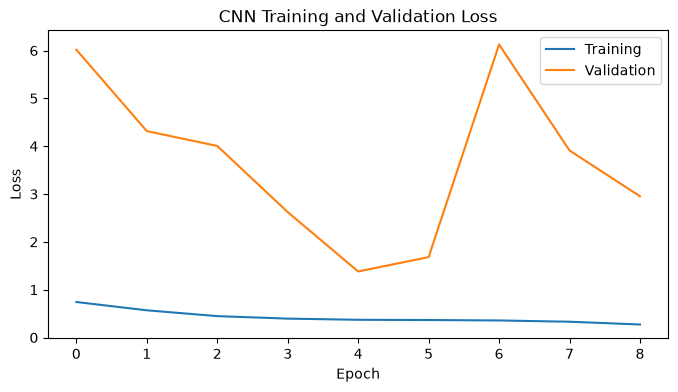

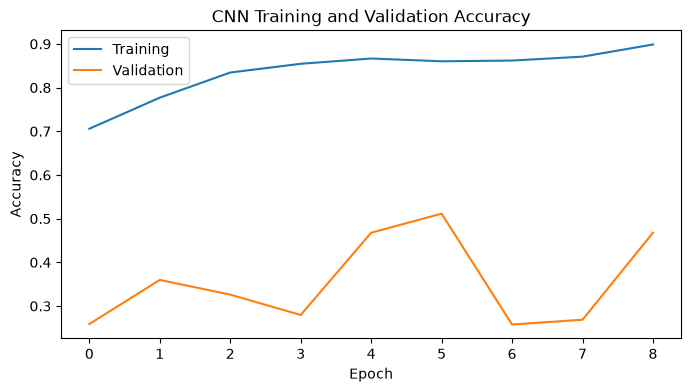

In [5]:
history_df = pd.DataFrame(history.history)

history_df.to_csv(
    MODELS_DIR / "training_history.csv",
    index=False
)

plt.figure(figsize=(8, 4))

plt.plot(history.history["loss"], label="Training")
plt.plot(history.history["val_loss"], label="Validation")

plt.title("CNN Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

plt.figure(figsize=(8, 4))

plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")

plt.title("CNN Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()


# Experiment V2 — Data Augmentation

In [6]:

from pathlib import Path
import shutil

MODELS_DIR = PROJECT_ROOT / "models"
V1_DIR = MODELS_DIR / "experiments" / "v1_baseline"
V2_DIR = PROJECT_ROOT / "models" / "experiments" / "v2_augmentation"


V1_DIR.mkdir(parents=True, exist_ok=True)
V2_DIR.mkdir(parents=True, exist_ok=True)

files_to_backup = [
    MODELS_DIR / "best_cnn.keras",
    MODELS_DIR / "training_history.csv",
    MODELS_DIR / "test_report.txt",
    PROJECT_ROOT / "data/splits/split_manifest.csv"
]

for source in files_to_backup:
    if source.exists():
        destination = V1_DIR / source.name

        if not destination.exists():
            shutil.copy2(source, destination)

        print("Preserved:", destination.name)
    else:
        print("Missing:", source.name)


Preserved: best_cnn.keras
Preserved: training_history.csv
Preserved: test_report.txt
Preserved: split_manifest.csv


In [7]:

from src.brainscan import build_model

tf.keras.utils.set_random_seed(42)

layers = tf.keras.layers

augmentation = tf.keras.Sequential([
    layers.RandomRotation(
        factor=0.025,
        fill_mode="constant",
        fill_value=0.0,
        seed=42
    ),
    layers.RandomZoom(
        height_factor=0.05,
        fill_mode="constant",
        fill_value=0.0,
        seed=43
    )
], name="augmentation")

model_v2 = tf.keras.Sequential([
    tf.keras.Input(shape=(224, 224, 1)),
    augmentation,
    build_model()
], name="brainscan_v2")

model_v2.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model_v2.summary(expand_nested=True)


Model: "brainscan_v2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ augmentation (Sequential)       │ (None, 224, 224, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ random_rotation            │ (None, 224, 224, 1)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ random_zoom (RandomZoom)   │ (None, 224, 224, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential_1 (Sequential)       │ (None, 4)              │       291,396 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ conv2d_4 (Conv2D)          │ (None, 224, 224, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ batch_normalization_4      │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ max_pooling2d_3            │ (None, 112, 112, 32)   │             0 │
│ (MaxPooling2D)                  │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ conv2d_5 (Conv2D)          │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ batch_normalization_5      │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ max_pooling2d_4            │ (None, 56, 56, 64)     │             0 │
│ (MaxPooling2D)                  │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ conv2d_6 (Conv2D)          │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ batch_normalization_6      │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ max_pooling2d_5            │ (None, 28, 28, 128)    │             0 │
│ (MaxPooling2D)                  │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ conv2d_7 (Conv2D)          │ (None, 28, 28, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ batch_normalization_7      │ (None, 28, 28, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ global_average_pooling2d_1 │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ dense_3 (Dense)            │ (None, 256)            │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ dropout_2 (Dropout)        │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ dense_4 (Dense)            │ (None, 64)             │        16,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ dropout_3 (Dropout)        │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 291,396 (1.11 MB)

 Trainable params: 290,692 (1.11 MB)

 Non-trainable params: 704 (2.75 KB)

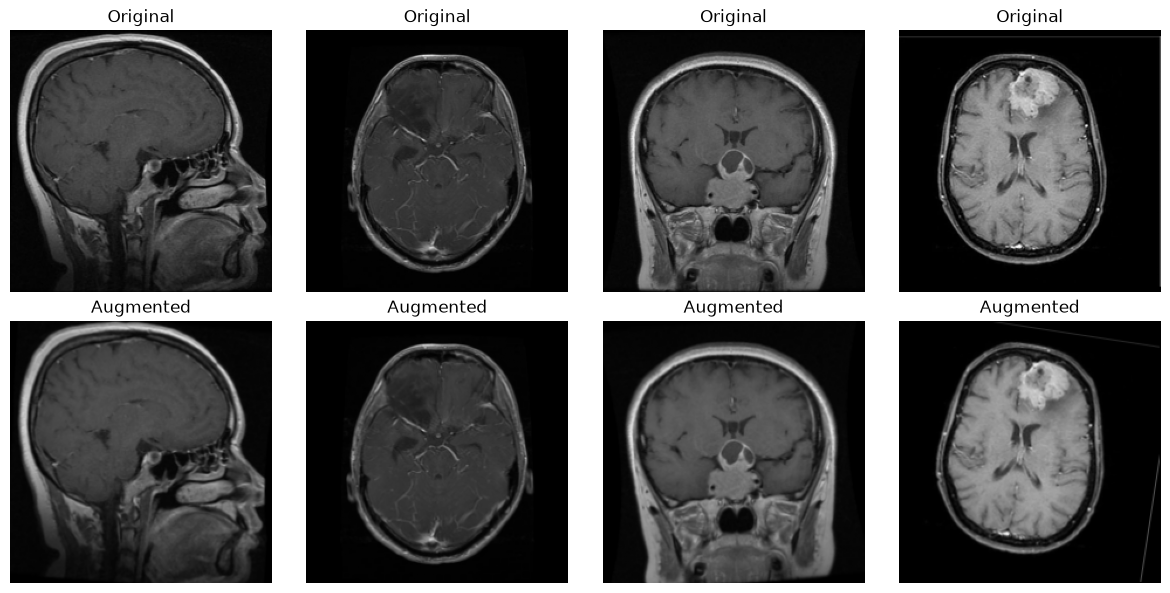

In [8]:

import matplotlib.pyplot as plt

images, labels = next(iter(train_ds))

original = images[:4]

augmented = augmentation(
    original,
    training=True
)

fig, axes = plt.subplots(
    2, 4,
    figsize=(12, 6)
)

for i in range(4):
    axes[0, i].imshow(
        original[i].numpy().squeeze(),
        cmap="gray",
        vmin=0,
        vmax=1
    )
    axes[0, i].set_title("Original")
    axes[0, i].axis("off")

    axes[1, i].imshow(
        augmented[i].numpy().squeeze(),
        cmap="gray",
        vmin=0,
        vmax=1
    )
    axes[1, i].set_title("Augmented")
    axes[1, i].axis("off")

plt.tight_layout()
plt.show()


In [9]:
import time
import pandas as pd
import tensorflow as tf

V2_DIR = PROJECT_ROOT / "models" / "experiments" / "v2_augmentation"
V2_DIR.mkdir(parents=True, exist_ok=True)

callbacks_v2 = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True
    ),
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(V2_DIR / "best_cnn.keras"),
        monitor="val_loss",
        save_best_only=True
    )
]

start = time.perf_counter()

history_v2 = model_v2.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=callbacks_v2
)

duration = time.perf_counter() - start

pd.DataFrame(history_v2.history).to_csv(
    V2_DIR / "training_history.csv",
    index=False
)

print(f"Training duration: {duration:.2f} seconds")
print("V2 model saved:", V2_DIR / "best_cnn.keras")
print("V2 history saved:", V2_DIR / "training_history.csv")


Epoch 1/15


/home/houssam/Desktop/Briefs/Brief 4/.venv-gpu/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


    148/Unknown 19s 74ms/step - accuracy: 0.7016 - loss: 0.7396

I0000 00:00:1792167439.913991  128387 local_rendezvous.cc:436] Local rendezvous send item cancelled. Key hash: 9872460204728128714
I0000 00:00:1792167439.914017  128387 local_rendezvous.cc:436] Local rendezvous send item cancelled. Key hash: 17873255892800639749
I0000 00:00:1792167439.914021  128387 local_rendezvous.cc:436] Local rendezvous send item cancelled. Key hash: 13981003779996810717
I0000 00:00:1792167439.914039  128387 local_rendezvous.cc:432] Local rendezvous recv item cancelled. Key hash: 3497635891848538686
I0000 00:00:1792167439.914045  128387 local_rendezvous.cc:432] Local rendezvous recv item cancelled. Key hash: 13259180292806704258
I0000 00:00:1792167439.914049  128387 local_rendezvous.cc:432] Local rendezvous recv item cancelled. Key hash: 2743752409640771240
I0000 00:00:1792167439.914052  128387 local_rendezvous.cc:436] Local rendezvous send item cancelled. Key hash: 9496036411041676850
/home/houssam/Desktop/Briefs/Brief 4/.venv-gpu/lib/python3.12/site-packages/kera

148/148 ━━━━━━━━━━━━━━━━━━━━ 21s 88ms/step - accuracy: 0.7016 - loss: 0.7396 - val_accuracy: 0.2587 - val_loss: 5.9878
Epoch 2/15


...

147/148 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step - accuracy: 0.8793 - loss: 0.3303

I0000 00:00:1792167547.806061  128387 local_rendezvous.cc:436] Local rendezvous send item cancelled. Key hash: 14835136146446438622
I0000 00:00:1792167547.806099  128387 local_rendezvous.cc:432] Local rendezvous recv item cancelled. Key hash: 3497635891848538686
I0000 00:00:1792167547.806108  128387 local_rendezvous.cc:432] Local rendezvous recv item cancelled. Key hash: 13259180292806704258
I0000 00:00:1792167547.806111  128387 local_rendezvous.cc:436] Local rendezvous send item cancelled. Key hash: 9872460204728128714
I0000 00:00:1792167547.806117  128387 local_rendezvous.cc:432] Local rendezvous recv item cancelled. Key hash: 2743752409640771240
I0000 00:00:1792167547.806121  128387 local_rendezvous.cc:436] Local rendezvous send item cancelled. Key hash: 9496036411041676850


148/148 ━━━━━━━━━━━━━━━━━━━━ 13s 85ms/step - accuracy: 0.8794 - loss: 0.3301 - val_accuracy: 0.6383 - val_loss: 1.0469
Epoch 10/15


I0000 00:00:1792167549.535310  128674 local_rendezvous.cc:432] Local rendezvous recv item cancelled. Key hash: 9476305155468915233
I0000 00:00:1792167549.535335  128674 local_rendezvous.cc:432] Local rendezvous recv item cancelled. Key hash: 13655676728236030698
I0000 00:00:1792167549.535366  128674 local_rendezvous.cc:432] Local rendezvous recv item cancelled. Key hash: 14344119985746834338


148/148 ━━━━━━━━━━━━━━━━━━━━ 13s 84ms/step - accuracy: 0.8923 - loss: 0.2968 - val_accuracy: 0.3875 - val_loss: 2.7489
Training duration: 141.94 seconds
V2 model saved: /home/houssam/Desktop/Briefs/Brief 4/models/experiments/v2_augmentation/best_cnn.keras
V2 history saved: /home/houssam/Desktop/Briefs/Brief 4/models/experiments/v2_augmentation/training_history.csv


In [10]:

v1_history = pd.read_csv(
    V1_DIR / "training_history.csv"
)

v2_history = pd.read_csv(
    V2_DIR / "training_history.csv"
)

for name, history_df in [
    ("Baseline V1", v1_history),
    ("Augmented V2", v2_history)
]:
    best_index = history_df["val_loss"].idxmin()
    best_epoch = history_df.loc[best_index]

    print(f"\n{name}")
    print("Best epoch:", best_index + 1)
    print(
        "Validation accuracy:",
        f"{best_epoch['val_accuracy']:.2%}"
    )
    print(
        "Validation loss:",
        f"{best_epoch['val_loss']:.4f}"
    )



Baseline V1
Best epoch: 13
Validation accuracy: 81.57%
Validation loss: 0.4461

Augmented V2
Best epoch: 6
Validation accuracy: 64.72%
Validation loss: 0.8713


# Experiment V3 — Learning Rate Scheduler

In [11]:

import time
import pandas as pd
import tensorflow as tf

V3_DIR = PROJECT_ROOT / "models" / "experiments" / "v3_scheduler"
V3_DIR.mkdir(parents=True, exist_ok=True)

# Rebuild the original CNN without augmentation
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)

model_v3 = build_model()

model_v3.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

callbacks_v3 = [
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6,
        verbose=1
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True
    ),

    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(V3_DIR / "best_cnn.keras"),
        monitor="val_loss",
        save_best_only=True
    )
]

start = time.perf_counter()

history_v3 = model_v3.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=callbacks_v3,
    shuffle=False
)

duration = time.perf_counter() - start

pd.DataFrame(history_v3.history).to_csv(
    V3_DIR / "training_history.csv",
    index=False
)

print(f"Training duration: {duration:.2f} seconds")


Epoch 1/15


I0000 00:00:1792167566.077499  125990 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_31363__.67


    147/Unknown 14s 56ms/step - accuracy: 0.7173 - loss: 0.7301

I0000 00:00:1792167577.681347  125990 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_31363__.67


    148/Unknown 17s 79ms/step - accuracy: 0.7169 - loss: 0.7312

...

I0000 00:00:1792167719.902770  130381 local_rendezvous.cc:432] Local rendezvous recv item cancelled. Key hash: 3360614866432301505
I0000 00:00:1792167719.902812  130381 local_rendezvous.cc:432] Local rendezvous recv item cancelled. Key hash: 6913495305468277064


146/148 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - accuracy: 0.9495 - loss: 0.1412

I0000 00:00:1792167727.569415  130193 local_rendezvous.cc:432] Local rendezvous recv item cancelled. Key hash: 3360614866432301505
I0000 00:00:1792167727.569442  130193 local_rendezvous.cc:432] Local rendezvous recv item cancelled. Key hash: 6913495305468277064


148/148 ━━━━━━━━━━━━━━━━━━━━ 9s 56ms/step - accuracy: 0.9497 - loss: 0.1413 - val_accuracy: 0.9296 - val_loss: 0.2159 - learning_rate: 6.2500e-05
Training duration: 165.84 seconds


I0000 00:00:1792167728.964377  130381 local_rendezvous.cc:432] Local rendezvous recv item cancelled. Key hash: 3360614866432301505
I0000 00:00:1792167728.964429  130381 local_rendezvous.cc:432] Local rendezvous recv item cancelled. Key hash: 6913495305468277064
